# Homework 3– From an MD Trajectory to a Defensible Diffusion Coefficient

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
def initialize_lattice(n_particles, box_length):
    """Place particles on a square lattice to avoid initial overlaps."""
    n_side = int(np.ceil(np.sqrt(n_particles)))
    spacing = box_length / n_side
    coords = np.arange(n_side) * spacing + 0.5 * spacing
    positions = np.array([(x, y) for x in coords for y in coords], dtype=float)
    return positions[:n_particles]


def lj_forces_and_energy(positions_wrapped, box_length):
    """Return Lennard-Jones forces and potential energy in reduced units."""
    r = positions_wrapped

    # Pair displacement r_i - r_j
    dr = r[:, None, :] - r[None, :, :]

    # Minimum-image convention for periodic boundaries
    dr -= box_length * np.rint(dr / box_length)

    r2 = np.sum(dr**2, axis=2)
    np.fill_diagonal(r2, np.inf)

    inv_r2 = 1.0 / r2
    inv_r6 = inv_r2**3

    # F_ij = 24 [2 r^-14 - r^-8] r_ij
    prefactor = 24.0 * inv_r2 * (2.0 * inv_r6**2 - inv_r6)
    prefactor[np.isinf(r2)] = 0.0
    forces = np.sum(prefactor[:, :, None] * dr, axis=1)

    # Pair potential; factor 1/2 removes double counting
    pair_u = 4.0 * (inv_r6**2 - inv_r6)
    np.fill_diagonal(pair_u, 0.0)
    potential_energy = 0.5 * np.sum(pair_u)

    return forces, potential_energy


def run_position_verlet(
    dt,
    total_time=30.0,
    n_particles=36,
    density=0.65,
    initial_temperature=1.0,
    sample_dt=0.05,
    seed=504,
):
    """Run a 2D NVE Lennard-Jones simulation using position Verlet."""
    box_length = np.sqrt(n_particles / density)
    positions0 = initialize_lattice(n_particles, box_length)

    rng = np.random.default_rng(seed)

    # Initial velocities; remove center-of-mass motion
    velocities0 = rng.normal(size=(n_particles, 2))
    velocities0 -= velocities0.mean(axis=0)

    # Scale the initial kinetic temperature to the requested value
    dof = 2 * n_particles - 2
    current_T = np.sum(velocities0**2) / dof
    velocities0 *= np.sqrt(initial_temperature / current_T)

    # Initial acceleration
    forces0, _ = lj_forces_and_energy(positions0, box_length)
    acceleration0 = forces0  # m = 1 in reduced units

    # Position at t = -dt, obtained from a Taylor expansion
    r_current = positions0.copy()          # unwrapped coordinates
    r_previous = (
        r_current
        - velocities0 * dt
        + 0.5 * acceleration0 * dt**2
    )

    n_steps = int(round(total_time / dt))
    sample_every = max(1, int(round(sample_dt / dt)))

    times = []
    trajectory = []
    total_energy = []

    for step in range(n_steps):
        # Wrap only for force evaluation
        r_wrapped = np.mod(r_current, box_length)
        forces, potential_energy = lj_forces_and_energy(r_wrapped, box_length)
        acceleration = forces  # m = 1

        # Position-Verlet / central-difference update
        r_new = 2.0 * r_current - r_previous + acceleration * dt**2

        # Central-difference velocity at the current time
        velocity = (r_new - r_previous) / (2.0 * dt)
        kinetic_energy = 0.5 * np.sum(velocity**2)

        if step % sample_every == 0:
            times.append(step * dt)
            trajectory.append(r_current.copy())
            total_energy.append(kinetic_energy + potential_energy)

        r_previous, r_current = r_current, r_new

    return {
        "time": np.asarray(times),
        "trajectory": np.asarray(trajectory),
        "energy": np.asarray(total_energy),
        "box_length": box_length,
        "dt": dt,
    }


## Part 1– Independent production trajectories

a. Why are different initial velocities / random seeds useful when checking convergence?

Different random seeds generate different initial velocities, producing independent trajectories. Comparing their results helps assess whether the estimated equilibrium properties are reproducible and sufficiently sampled rather than dependent on one particular trajectory.

b. Should the two trajectories be identical? Should estimates of the same equilibrium transport property be reasonably consistent if sampling is adequate?

No, the trajectories should not be identical because they start with different velocities. However, if sampling is adequate, both should produce reasonably consistent estimates of the same equilibrium transport property, such as the diffusion coefficient.

In [5]:
replica_1 = run_position_verlet(dt=.005,seed=504)
replica_2 = run_position_verlet(dt=.005,seed=509)

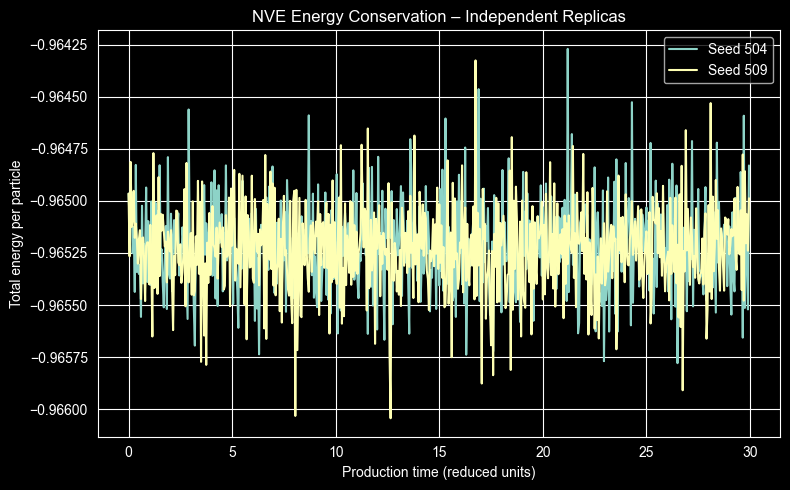

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    replica_1["time"],
    replica_1["energy"] / 36,
    label="Seed 504"
)

plt.plot(
    replica_2["time"],
    replica_2["energy"] / 36,
    label="Seed 509"
)

plt.xlabel("Production time (reduced units)")
plt.ylabel("Total energy per particle")
plt.title("NVE Energy Conservation – Independent Replicas")
plt.legend()
plt.tight_layout()
plt.show()

Comment on whether either
production trajectory shows obvious systematic energy drift, and explain why this check should be
made before analyzing diffusion

The total energy per particle remains approximately constant throughout both NVE trajectories, with small numerical fluctuations and no obvious systematic drift. This indicates reasonable energy conservation during the simulations. Checking energy conservation before analyzing diffusion is important because significant energy drift may indicate numerical integration errors or unstable dynamics, which could make the calculated diffusion coefficient unreliable.

## Part 2– Wrapped versus unwrapped motion

In [10]:
## part 2_1
unwrapped_tr = replica_1["trajectory"]
box_length = replica_1["box_length"]

wrapped_tr = np.mod(unwrapped_tr, box_length)

In [11]:
## part 2_2
def time_origin_averaged_msd(trajectory, max_lag=300):
    n_frames = trajectory.shape[0]
    max_lag = min(max_lag, n_frames - 1)

    msd = np.zeros(max_lag + 1)

    for lag in range(1, max_lag + 1):
        displacement = trajectory[lag:] - trajectory[:-lag]
        squared_displacement = np.sum(displacement**2, axis=2)
        msd[lag] = np.mean(squared_displacement)

    return msd

msd_unwrapped = time_origin_averaged_msd(unwrapped_tr,max_lag=300)
msd_wrapped = time_origin_averaged_msd(wrapped_tr,max_lag=300)

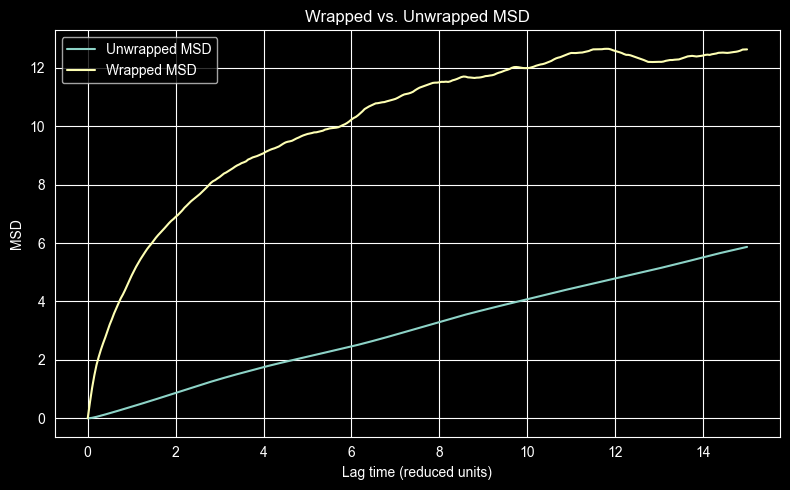

In [12]:
# part 3_2
lag_times = replica_1["time"][:301] - replica_1["time"][0]

plt.figure(figsize=(8, 5))
plt.plot(lag_times, msd_unwrapped, label="Unwrapped MSD")
plt.plot(lag_times, msd_wrapped, label="Wrapped MSD")

plt.xlabel("Lag time (reduced units)")
plt.ylabel("MSD")
plt.title("Wrapped vs. Unwrapped MSD")
plt.legend()
plt.tight_layout()
plt.show()

### Single-Origin MSD vs. Time-Origin-Averaged MSD

1\. Single-Origin MSD

- Uses only Frame 0 as the reference.
- Calculates the squared displacement of each particle relative to its initial position.
- Averages over all particles.
- For 500 frames, produces 500 MSD values (lags 0–499).
- Can be statistically noisy because it uses only one time origin.

2\. Time-Origin-Averaged MSD

- Uses multiple starting frames (time origins) instead of only Frame 0.
- For each lag, calculates squared displacements between all frame pairs separated by that lag.
- Averages over all valid time origins and particles.
- Generally provides a smoother, more statistically reliable MSD estimate.

Example: 500 frames with `max_lag=300`

| Lag | Number of frame pairs |
| --- | --------------------- |
| 1   | 499                   |
| 100 | 400                   |
| 300 | 200                   |

The result contains 301 MSD values (lags 0–300) if lag zero is included.

### Key takeaway

Single-origin MSD: One starting frame, multiple time lags.

Time-origin-averaged MSD: Multiple starting frames for each time lag, improving statistical sampling.

Both methods measure mean-squared displacement, but time-origin averaging generally reduces statistical noise and improves diffusion coefficient estimation.

a. Why is an MSD calculated directly from wrapped coordinates incorrect for long-time diffusion analysis?

Wrapped coordinates introduce artificial jumps when particles cross periodic boundaries. These jumps do not represent their actual continuous motion, so the calculated MSD becomes incorrect for long-time diffusion analysis.

b. Which coordinate representation should be used to preserve physical translational displacement?

Unwrapped coordinates should be used because they preserve the continuous displacement of particles across periodic boundaries.

## Part 3– Obtain the diffusion coefficient

In [18]:
#3-1 For each replica, calculate the unwrapped MSD and fit the supplied interval
unwrapped_tr_1 = replica_1["trajectory"]

replica_1_msd = time_origin_averaged_msd(unwrapped_tr_1, max_lag=300)

unwrapped_tr_2 = replica_2["trajectory"]

replica_2_msd = time_origin_averaged_msd(unwrapped_tr_2,max_lag=300)



In [19]:
# 3_1 fit the line
fit_mask = (lag_times >= 2) & (lag_times <= 8)
lag_times = replica_1["time"][:301] - replica_1["time"][0]

slope1, intercept1 = np.polyfit(
    lag_times[fit_mask],
    replica_1_msd[fit_mask],
    1
)

slope2, intercept2 = np.polyfit(
    lag_times[fit_mask],
    replica_2_msd[fit_mask],
    1
)

D1 = slope1 / 4
D2 = slope2 / 4

print("D1 =", D1)
print("D2 =", D2)

D1 = 0.0967947642782091
D2 = 0.11766494247032237


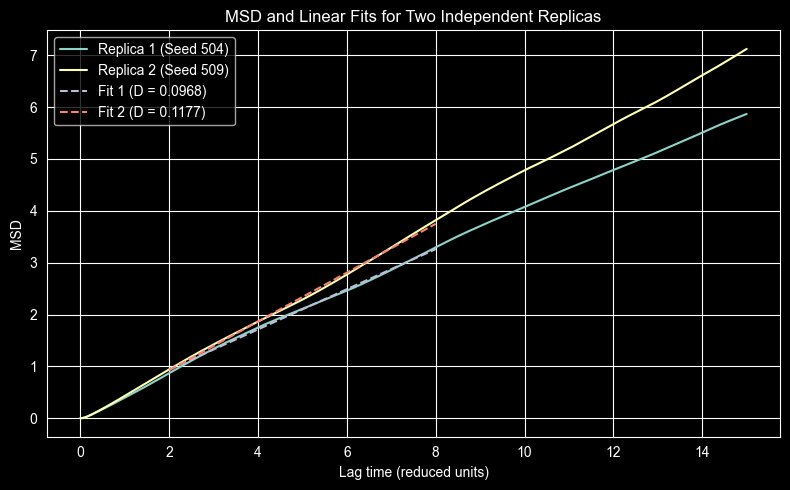

D1 = 0.0968
D2 = 0.1177


In [20]:
plt.figure(figsize=(8, 5))

# Plot both complete MSD curves
plt.plot(lag_times, replica_1_msd, label="Replica 1 (Seed 504)")
plt.plot(lag_times, replica_2_msd, label="Replica 2 (Seed 509)")

# Plot fitted lines only within 2 <= t <= 8
plt.plot(
    lag_times[fit_mask],
    slope1 * lag_times[fit_mask] + intercept1,
    "--", label=f"Fit 1 (D = {D1:.4f})"
)

plt.plot(
    lag_times[fit_mask],
    slope2 * lag_times[fit_mask] + intercept2,
    "--", label=f"Fit 2 (D = {D2:.4f})"
)

plt.xlabel("Lag time (reduced units)")
plt.ylabel("MSD")
plt.title("MSD and Linear Fits for Two Independent Replicas")
plt.legend()
plt.tight_layout()
plt.show()

print(f"D1 = {D1:.4f}")
print(f"D2 = {D2:.4f}")

a. Why is D obtained from the slope rather than from a single displacement value?

The diffusion coefficient describes the average rate at which the mean squared displacement increases with time. Using the slope of the MSD curve provides a more reliable estimate than using a single displacement value, which may be affected by statistical fluctuations.

b. Why is a specified fitting interval useful in this introductory homework?

A specified fitting interval ensures that both replicas are analyzed consistently and avoids subjective selection of different fitting regions. It also helps focus the analysis on the intended approximately linear diffusion regime.

c. Why might very short or very long lag times be unsuitable for estimating a long-time diffusion coefficient?

At very short lag times, particle motion may still be ballistic rather than diffusive, so the MSD is not linear in time. At very long lag times, fewer independent time origins contribute to the MSD, increasing statistical uncertainty.

## Part 4– Replica agreement and convergence judgment

In [23]:
D_mean = (D1+D2)/2
diff = (np.abs(D1-D2)/D_mean) * 100

print(f"D1 = {D1:.4f}")
print(f"D2 = {D2:.4f}")
print(f"D_mean = {D_mean:.4f}")
print(f"Percentage difference = {diff:.2f}%")

D1 = 0.0968
D2 = 0.1177
D_mean = 0.1072
Percentage difference = 19.46%


**a. Do the replicas give reasonably similar values of D? What does this agreement tell you, and what does it not prove?**

The two replicas give diffusion coefficients of 0.0968 and 0.1177, with a percentage difference of 19.46%. The values are reasonably similar in magnitude but show noticeable variability. This suggests some reproducibility between independent simulations, but it does not prove convergence. Longer simulations or additional replicas may be needed to assess statistical uncertainty and improve confidence in the results.

**b. If temperature appeared perfectly stable but the two replicas gave very different values of D, would you call D converged? Explain.**

No. Stable temperature indicates stable thermal behavior but does not guarantee convergence of transport properties. Large differences between the diffusion coefficients suggest insufficient sampling and indicate that D has not been estimated reproducibly.

**c. If the scientific objective were instead to obtain the equilibrium density at specified temperature and pressure, which ensemble would be more appropriate: NVE, NVT, or NPT? Explain in one sentence.**

The NPT ensemble is most appropriate because it maintains the specified temperature and pressure while allowing the system volume to fluctuate, enabling the equilibrium density to be determined.

#### Final Synthesis
A trustworthy diffusion coefficient requires a proper simulation protocol, including NVT equilibration followed by NVE production to avoid thermostat effects on particle dynamics. Under periodic boundary conditions, unwrapped coordinates must be used to calculate MSD correctly, since wrapped coordinates introduce artificial jumps in particle displacement. The diffusion coefficient should be obtained from the slope of the MSD in the linear diffusive regime, avoiding very short or excessively long lag times. Independent replicas are also important for checking reproducibility and statistical convergence. In our results, the 19.46% difference between the two replicas indicates noticeable variability, suggesting that additional sampling may be needed to improve confidence in the estimated diffusion coefficient.